# 01 · Analyse exploratoire de `application_train`

**Objectif :** comprendre les données avant de modéliser.

1. Structure : taille, types de variables
2. La cible : combien de défauts ?
3. Valeurs manquantes
4. Anomalies à corriger
5. Variables les plus liées au défaut
6. Variables catégorielles : taux de défaut par catégorie
7. Conclusions pour la suite

Une ligne correspond à **une demande de crédit**. `TARGET = 1` signifie que le client a eu des difficultés de paiement (défaut).

In [1]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from credit_risk_scoring.config import DUCKDB_PATH, FIGURES, TARGET

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
FIGURES.mkdir(parents=True, exist_ok=True)

with duckdb.connect(str(DUCKDB_PATH), read_only=True) as con:
    df = con.execute("SELECT * FROM application_train").df()
df.shape

(307511, 122)

## 1. Structure des données

In [2]:
df.dtypes.astype(str).value_counts()

float64    65
int64      41
str        15
boolean     1
Name: count, dtype: int64

In [3]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.028663,-19932,-3038,-4311.0,-3458,NaN,1,1,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


Les colonnes `DAYS_*` sont des **nombres de jours comptés à rebours depuis la date de la demande** (valeurs négatives).
Par exemple, `DAYS_BIRTH = -12000` correspond à un client de 12000 / 365 ≈ 33 ans.

## 2. La cible : un problème déséquilibré

Remboursé (0) : 282,686
Défaut    (1) :  24,825
Taux de défaut : 8.07%


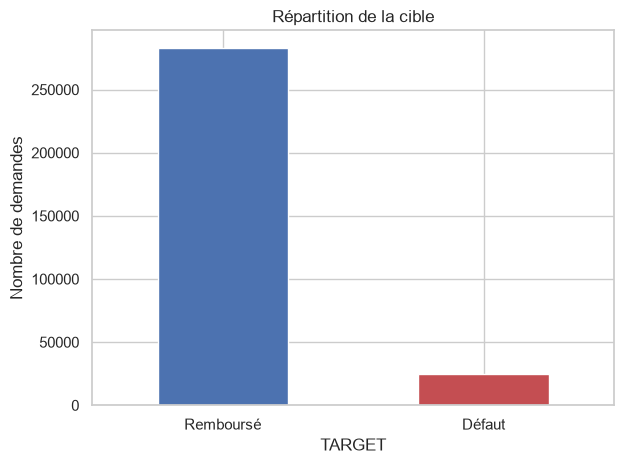

In [4]:
counts = df[TARGET].value_counts()
rate = df[TARGET].mean()
print(f"Remboursé (0) : {counts[0]:>7,}")
print(f"Défaut    (1) : {counts[1]:>7,}")
print(f"Taux de défaut : {rate:.2%}")

ax = counts.rename({0: "Remboursé", 1: "Défaut"}).plot.bar(color=["#4C72B0", "#C44E52"], rot=0)
ax.set_title("Répartition de la cible")
ax.set_ylabel("Nombre de demandes")
plt.tight_layout(); plt.savefig(FIGURES / "01_cible.png", dpi=120); plt.show()

**À retenir :** un modèle qui prédit « remboursé » pour tout le monde aurait environ 92 % de bonnes réponses… tout en étant inutile.
On n'utilisera donc **pas l'accuracy**, mais l'**AUC**, le **Gini** (= 2 × AUC − 1) et le **KS**, les indicateurs utilisés en scoring bancaire.

## 3. Valeurs manquantes

In [5]:
na = df.isna().mean().sort_values(ascending=False)
print(f"Colonnes avec des valeurs manquantes : {(na > 0).sum()} / {df.shape[1]}")
print(f"Colonnes avec plus de 50 % de manquants : {(na > 0.5).sum()}")
na[na > 0].head(20).to_frame("taux_manquant").style.format("{:.1%}")

Colonnes avec des valeurs manquantes : 67 / 122
Colonnes avec plus de 50 % de manquants : 41


,taux_manquant
COMMONAREA_AVG,69.9%
COMMONAREA_MODE,69.9%
COMMONAREA_MEDI,69.9%
NONLIVINGAPARTMENTS_MEDI,69.4%
NONLIVINGAPARTMENTS_MODE,69.4%
NONLIVINGAPARTMENTS_AVG,69.4%
FONDKAPREMONT_MODE,68.4%
LIVINGAPARTMENTS_AVG,68.4%
LIVINGAPARTMENTS_MEDI,68.4%
LIVINGAPARTMENTS_MODE,68.4%


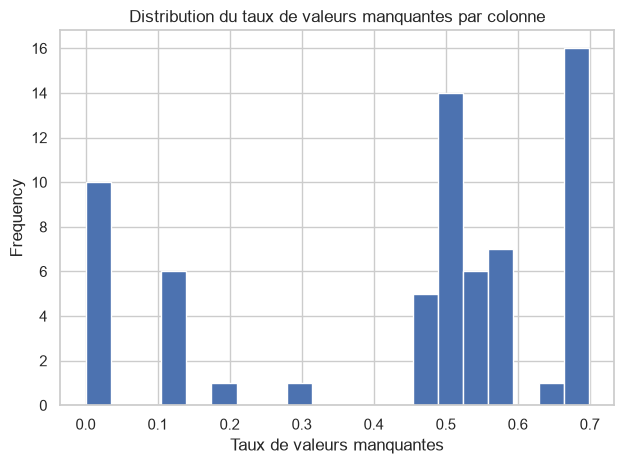

In [6]:
ax = na[na > 0].plot.hist(bins=20, color="#4C72B0")
ax.set_title("Distribution du taux de valeurs manquantes par colonne")
ax.set_xlabel("Taux de valeurs manquantes")
plt.tight_layout(); plt.savefig(FIGURES / "01_manquants.png", dpi=120); plt.show()

Beaucoup des colonnes très incomplètes décrivent **le logement** (suffixes `_AVG`, `_MODE`, `_MEDI`).

Une valeur manquante **peut être une information** : un client qui ne renseigne pas son logement n'a peut-être pas le même risque.
Vérifions-le en comparant le taux de défaut quand l'information est présente ou absente.

In [7]:
cols = ["EXT_SOURCE_1", "EXT_SOURCE_3", "OWN_CAR_AGE", "OCCUPATION_TYPE", "APARTMENTS_AVG"]
pd.DataFrame({
    "taux_manquant": [df[c].isna().mean() for c in cols],
    "défaut_si_manquant": [df.loc[df[c].isna(), TARGET].mean() for c in cols],
    "défaut_si_renseigné": [df.loc[df[c].notna(), TARGET].mean() for c in cols],
}, index=cols).style.format("{:.1%}")

,taux_manquant,défaut_si_manquant,défaut_si_renseigné
EXT_SOURCE_1,56.4%,8.5%,7.5%
EXT_SOURCE_3,19.8%,9.3%,7.8%
OWN_CAR_AGE,66.0%,8.5%,7.2%
OCCUPATION_TYPE,31.3%,6.5%,8.8%
APARTMENTS_AVG,50.7%,9.2%,7.0%


Les écarts sont nets : par exemple, l'absence d'information sur le logement (`APARTMENTS_AVG`) s'accompagne de plus de défauts,
alors qu'un métier non renseigné (`OCCUPATION_TYPE`) en montre moins (beaucoup de retraités, comme on va le voir).
Le fait que la valeur manque est donc **prédictif**.
Bonne nouvelle : la scorecard (découpage WoE) et LightGBM savent traiter les manquants comme une catégorie à part entière.
On ne supprimera donc pas ces colonnes trop vite.

## 4. Anomalies

### `DAYS_EMPLOYED` : la valeur 365243

In [8]:
anom = df["DAYS_EMPLOYED"] == 365243
print(f"Part des demandes avec DAYS_EMPLOYED = 365243 : {anom.mean():.1%}")
print(f"Taux de défaut avec la valeur anormale : {df.loc[anom, TARGET].mean():.2%}")
print(f"Taux de défaut sans                     : {df.loc[~anom, TARGET].mean():.2%}")
df.loc[anom, "NAME_INCOME_TYPE"].value_counts()

Part des demandes avec DAYS_EMPLOYED = 365243 : 18.0%
Taux de défaut avec la valeur anormale : 5.40%
Taux de défaut sans                     : 8.66%


NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64

365243 jours, c'est 1000 ans d'ancienneté : c'est un **code** et non une vraie valeur.
Il concerne presque uniquement des **retraités** (`Pensioner`), qui font moins défaut.

**Traitement prévu :** créer un indicateur `DAYS_EMPLOYED_ANOM` (0/1), puis remplacer 365243 par une valeur manquante.

### Autres valeurs suspectes

In [9]:
print("CODE_GENDER :", df["CODE_GENDER"].value_counts().to_dict())
print(df["AMT_INCOME_TOTAL"].describe().apply("{:,.0f}".format))

CODE_GENDER : {'F': 202448, 'M': 105059, 'XNA': 4}
count        307,511
mean         168,798
std          237,123
min           25,650
25%          112,500
50%          147,150
75%          202,500
max      117,000,000
Name: AMT_INCOME_TOTAL, dtype: str


- `CODE_GENDER = XNA` : 4 lignes seulement, à traiter comme des manquants.
- Revenus : la médiane est autour de 147 000, mais le maximum dépasse 100 millions. Il y a des **valeurs extrêmes** :
  on regardera les revenus sur une échelle logarithmique, et le découpage WoE les neutralisera.

> ⚠️ **Équité :** le genre (`CODE_GENDER`) est une donnée sensible. En Europe, l'utiliser pour décider d'un crédit pose des problèmes de discrimination (directive 2004/113/CE).
> On **l'exclura du modèle**, et on pourra vérifier plus tard que les décisions ne pénalisent pas un genre.

## 5. Variables numériques les plus liées au défaut

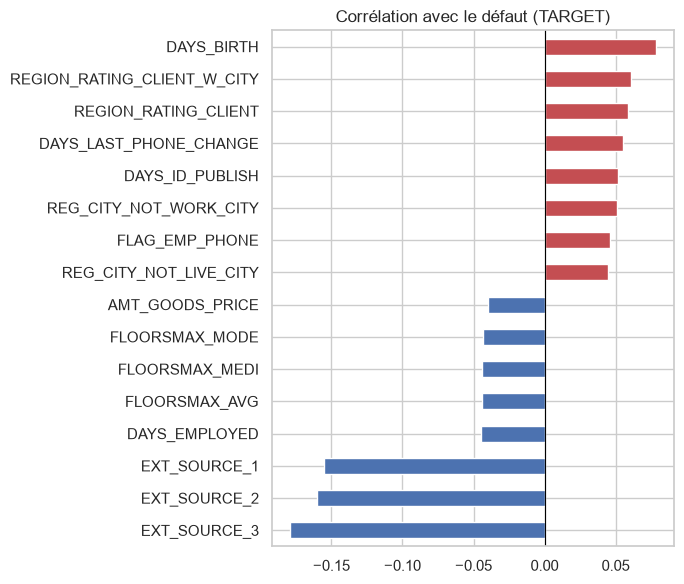

In [10]:
num = df.select_dtypes("number").drop(columns=["SK_ID_CURR", TARGET])
corr = num.corrwith(df[TARGET]).dropna().sort_values()
top = pd.concat([corr.head(8), corr.tail(8)])

ax = top.plot.barh(color=["#C44E52" if v > 0 else "#4C72B0" for v in top], figsize=(7, 6))
ax.set_title("Corrélation avec le défaut (TARGET)")
ax.axvline(0, color="black", lw=0.8)
plt.tight_layout(); plt.savefig(FIGURES / "01_correlations.png", dpi=120); plt.show()

Les trois variables `EXT_SOURCE_1/2/3` dominent. Ce sont des **scores externes** (fournis par d'autres organismes, comme un bureau de crédit) :
**plus le score est élevé, moins il y a de défaut**.

Les corrélations restent faibles (< 0,2 en valeur absolue) : aucune variable ne suffit seule, il faudra les **combiner**.

`DAYS_BIRTH` apparaît en rouge (corrélation positive) car il est **négatif** : un client plus jeune a un `DAYS_BIRTH` plus proche de 0, donc plus grand. La corrélation positive signifie donc que **les plus jeunes font plus défaut**, ce que confirme le graphique par âge ci-dessous.

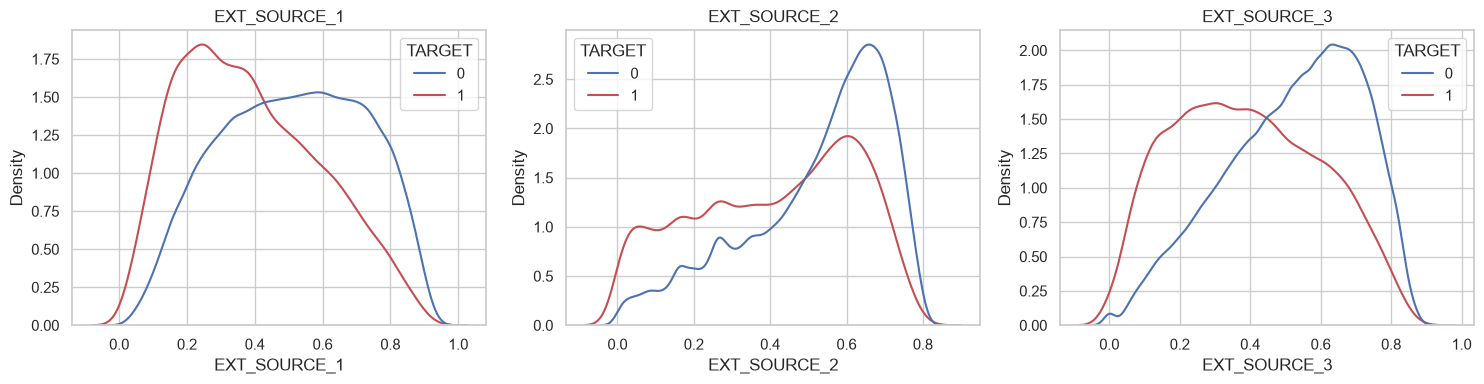

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]):
    sns.kdeplot(data=df, x=col, hue=TARGET, common_norm=False, ax=ax, palette=["#4C72B0", "#C44E52"])
    ax.set_title(col)
plt.tight_layout(); plt.savefig(FIGURES / "01_ext_sources.png", dpi=120); plt.show()

### L'âge

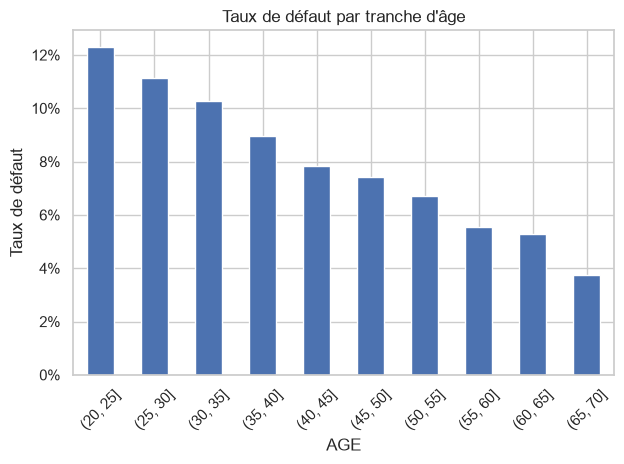

AGE
(20, 25]    12.3%
(25, 30]    11.1%
(30, 35]    10.3%
(35, 40]     8.9%
(40, 45]     7.8%
(45, 50]     7.4%
(50, 55]     6.7%
(55, 60]     5.5%
(60, 65]     5.3%
(65, 70]     3.7%
Name: TARGET, dtype: str

In [12]:
age = (-df["DAYS_BIRTH"] / 365).rename("AGE")
by_age = df[TARGET].groupby(pd.cut(age, bins=range(20, 75, 5)), observed=True).mean()

ax = by_age.plot.bar(color="#4C72B0", rot=45)
ax.set_title("Taux de défaut par tranche d'âge")
ax.set_ylabel("Taux de défaut")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout(); plt.savefig(FIGURES / "01_age.png", dpi=120); plt.show()
by_age.apply("{:.1%}".format)

Le risque **diminue nettement avec l'âge** : c'est un effet monotone, idéal pour une scorecard.

### Le poids du crédit par rapport au revenu

Corrélation linéaire avec le défaut :
CREDIT_INCOME_RATIO    -0.008
ANNUITY_INCOME_RATIO    0.014
CREDIT_TERM             0.013


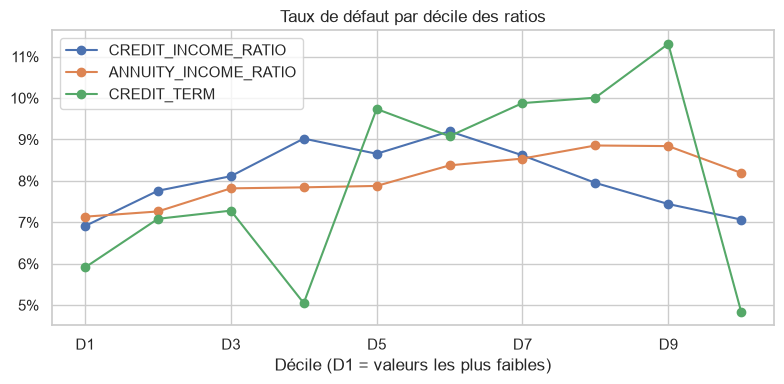

In [13]:
ratios = pd.DataFrame({
    "CREDIT_INCOME_RATIO": df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"],
    "ANNUITY_INCOME_RATIO": df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"],
    "CREDIT_TERM": df["AMT_ANNUITY"] / df["AMT_CREDIT"],
})
print("Corrélation linéaire avec le défaut :")
print(ratios.corrwith(df[TARGET]).round(3).to_string())

# Taux de défaut par décile : révèle les relations non linéaires
deciles = pd.DataFrame({
    col: df[TARGET].groupby(pd.qcut(ratios[col], 10, labels=False, duplicates="drop")).mean()
    for col in ratios
})
deciles.index = [f"D{i + 1}" for i in deciles.index]
ax = deciles.plot(marker="o", figsize=(8, 4))
ax.set_title("Taux de défaut par décile des ratios")
ax.set_xlabel("Décile (D1 = valeurs les plus faibles)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout(); plt.savefig(FIGURES / "01_ratios.png", dpi=120); plt.show()

Leur corrélation linéaire est quasi nulle… et pourtant le taux de défaut de `CREDIT_TERM` (mensualité / montant, donc l'inverse de la durée)
varie d'environ **5 % à 11 %** selon le décile, avec une forme **non monotone** (les crédits les plus longs comme les plus courts sont moins risqués).

**Leçon importante :** une corrélation proche de 0 ne veut pas dire « pas de lien ». Elle ne mesure que les relations linéaires.
Le découpage WoE et LightGBM captent ces formes non linéaires : on gardera ces ratios comme features.

## 6. Variables catégorielles : taux de défaut par catégorie

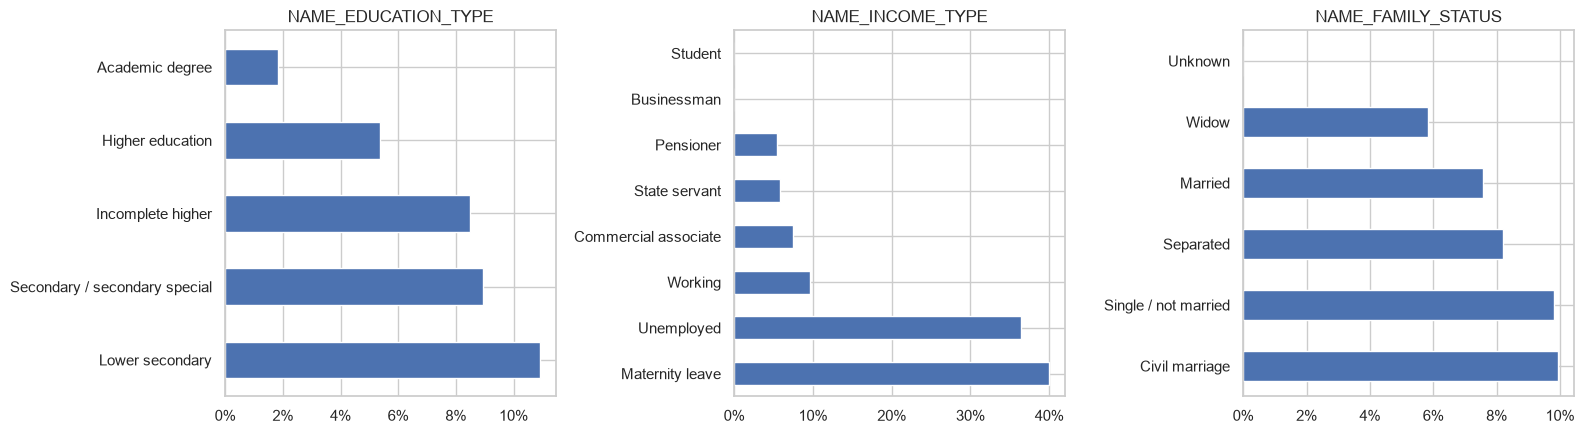

In [14]:
def default_rate(col):
    t = df.groupby(col, observed=True)[TARGET].agg(taux_defaut="mean", n="size")
    return t.sort_values("taux_defaut", ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE", "NAME_FAMILY_STATUS"]):
    default_rate(col)["taux_defaut"].plot.barh(ax=ax, color="#4C72B0")
    ax.set_title(col); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIGURES / "01_categorielles.png", dpi=120); plt.show()

In [15]:
default_rate("OCCUPATION_TYPE").style.format({"taux_defaut": "{:.1%}", "n": "{:,}"})

,taux_defaut,n
OCCUPATION_TYPE,,
Low-skill Laborers,17.2%,"2,093"
Drivers,11.3%,"18,603"
Waiters/barmen staff,11.3%,"1,348"
Security staff,10.7%,"6,721"
Laborers,10.6%,"55,186"
Cooking staff,10.4%,"5,946"
Sales staff,9.6%,"32,102"
Cleaning staff,9.6%,"4,653"
Realty agents,7.9%,751


Les écarts entre catégories sont importants (niveau d'études, type de revenu, métier).
Attention aux catégories **à faible effectif** : leur taux de défaut est peu fiable. Le découpage WoE les regroupera.
Exemple : *Maternity leave* (40 %) ou *Unemployed* (36 %) ne concernent qu'une poignée de demandes.

## 7. Conclusions et suite

| Constat | Conséquence pour la modélisation |
|---|---|
| Environ 8 % de défauts, classes déséquilibrées | Indicateurs AUC / Gini / KS, échantillonnage stratifié, pondération des classes |
| 67 colonnes avec des manquants, dont 41 à plus de 50 % | Garder les manquants comme information (WoE, LightGBM) plutôt que supprimer |
| `DAYS_EMPLOYED = 365243` (18 % des lignes, surtout des retraités) | Indicateur d'anomalie + remplacement par une valeur manquante |
| `EXT_SOURCE_1/2/3` sont les variables les plus prédictives | Variables centrales des deux modèles |
| Risque décroissant avec l'âge | Effet monotone, bien adapté à la scorecard |
| Revenus extrêmes ; ratios métier liés au défaut de façon non linéaire | Ratios crédit / revenu comme features, découpage en classes |
| `CODE_GENDER` est une donnée sensible | Exclue du modèle |

**Prochaine étape :** construire des features à partir des tables d'historique (`bureau`, `previous_application`, `installments_payments`…) en **SQL avec DuckDB**.